# Meteorologické družice a jejich srovnání

Jindřich Šťástka,
Družicové oddělení ČHMÚ

***
Tématický blok zaměřený na meteorologické družice, popisu hlavních rozdílů a práci s jejich daty.
***

Tento notebook Vám bude k dispozici pro zkoušení práce s daty na githubu [zde](https://github.com/CHMI-satellite-department/jupyter-notebooks).
***

## Rozdělení podle dráhy družice

https://www.youtube.com/watch?v=6Qf6VIvLGZk

- **geostacionární** dráha je taková, kde družice zdánlivě „pevně visí“ nad určitým místem zemského povrchu a je od něj vzdálená přibližně 35 790 km s oběžnou dráhou v rovině rovníku. Velkou výhodou je periodicita snímku (např. MSG až každých 5 minut - [Jak geostacionární družice skenuje](https://www.youtube.com/watch?v=f3XgfHSVBhc), MTG už skenuje trošku jinak a bude to umět i každých 2,5 minuty - trochu informaci pro milovníky komiksu [tady](https://www.youtube.com/watch?v=8KKmOOacZbM)  )

<img src="https://scijinks.gov/review/orbit/geo.gif">

- **polární** dráha je taková, kde družice oblétává Zemi s nějakou periodou např. 90 minut a Země se zatím pod ní pootočí. Meteorologické družice se nejčastěji pohybují na drahách ve vzdálenosti 700 - 900 km nad zemským povrchem. Periodicita snímku je nižsí, ale mívají lepší rozlišení.

<img src="https://scijinks.gov/review/orbit/leo.gif">

##Otázka: O snímek z jaké družice se jedná?

O snímek z jaké družice se jedná?

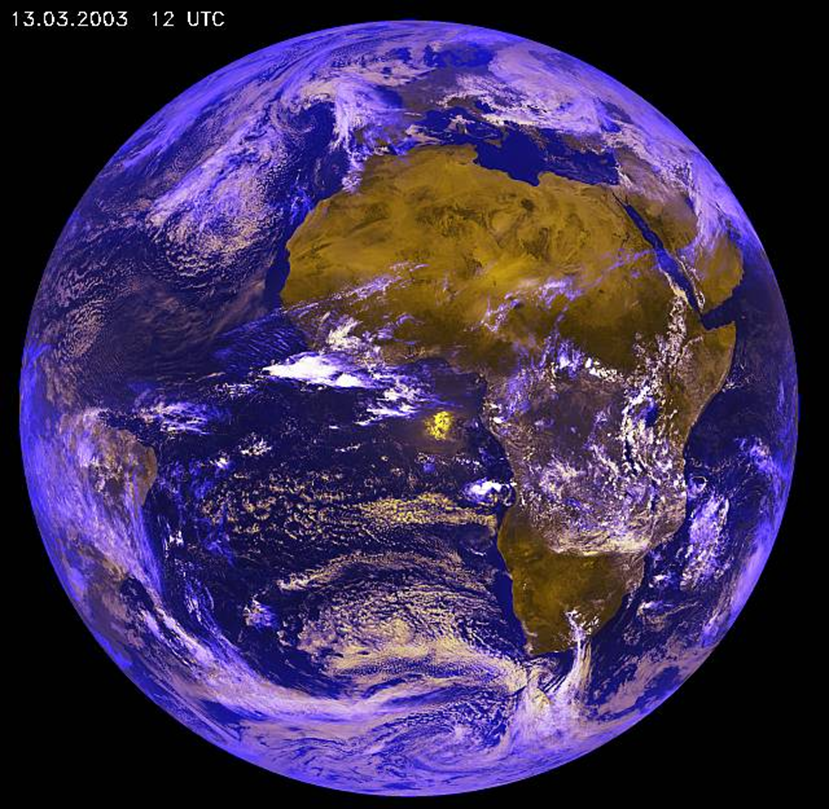

#Otázka: Co je žlutá skrvna uprostřed snímku?

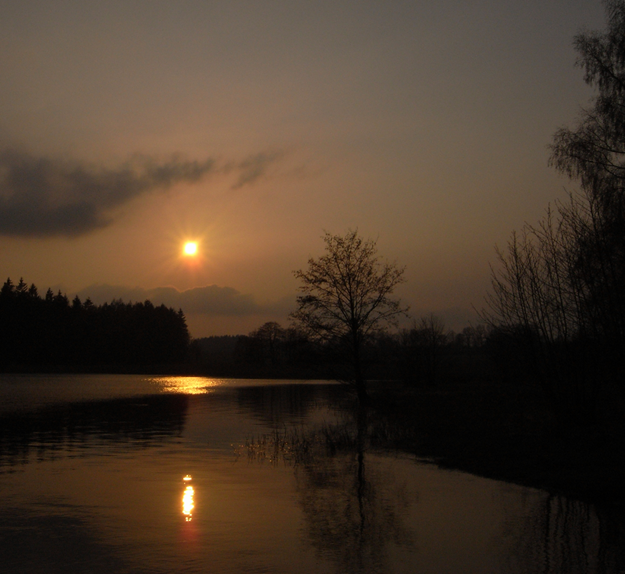

#Je na čase si na nějáka data zkusit šáhnout.

**Kde je vezmu?** Stáhnu si je z archivu [EUMETSATu](https://data.eumetsat.int/search?query=). Musím se nejdřív zaregistrovat. Můžu si to naklikat, nebo můžu použít knihovnu [eumdac](https://gitlab.eumetsat.int/eumetlab/data-services/eumdac.git)

In [ ]:
!pip install eumdac

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.5/75.5 kB 2.1 MB/s eta 0:00:00


In [ ]:
import eumdac
from datetime import datetime, timedelta
from google.colab import userdata
import requests
import shutil

# Get consumer key and secret from Colab Secrets Manager
# Add your EUMETSAT_CONSUMER_KEY and EUMETSAT_CONSUMER_SECRET to the Secrets Manager
try:
    consumer_key = userdata.get('EUMETSAT_CONSUMER_KEY')
    consumer_secret = userdata.get('EUMETSAT_CONSUMER_SECRET')

except Exception as e:
    print(f"Error retrieving credentials from Secrets Manager: {e}")
    print("Please add your EUMETSAT_CONSUMER_KEY and EUMETSAT_CONSUMER_SECRET to Colab's Secrets Manager.")
    consumer_key = None
    consumer_secret = None


if consumer_key and consumer_secret:
    # Create a Datastore object
    token = eumdac.AccessToken((consumer_key, consumer_secret))
    datastore = eumdac.DataStore(token)

    # Define the product ID for MSG Level 1.5 SEVIRI data
    # You can find product IDs on the EUMETSAT Data Store website
    # Make sure to replace this with the actual product ID for the data you want
    product_id = 'MSG-SEVIRI-MSG15-0100-NA' # This is an example product ID, check EUMETSAT for the correct one.

    # Define the time range for the last hour
    end_time = datetime.utcnow() # Get the current time in UTC
    start_time = end_time - timedelta(hours=0.25) # Calculate the start time one hour ago

    # Selecting the collection and product.
    selected_collection = datastore.get_collection('EO:EUM:DAT:MSG:HRSEVIRI')

    # Search for data
    try:
        selected_products = selected_collection.search(dtstart = start_time, dtend = end_time)
        print(f'Found Datasets: {selected_products.total_results} datasets for the given time range')

        # Download the products
        if selected_products:
            print(f"Found {len(selected_products)} products. Downloading...")
            for product in selected_products:
                print(f"Product: {product}")
                try:
                    with product.open() as fsrc, \
                        open(fsrc.name, mode='wb') as fdst:
                        shutil.copyfileobj(fsrc, fdst)
                    print(f'Download of product {product} is finished.')
                except eumdac.product.ProductError as error:
                    print(f"Error related to the product '{product}' while trying to download it: '{error.msg}'")
                except requests.exceptions.ConnectionError as error:
                    print(f"Error related to the connection: '{error.msg}'")
                except requests.exceptions.RequestException as error:
                    print(f"Unexpected error: {error}")
        else:
            print("No products found for the specified criteria.")

    except Exception as e:
        print(f"An error occurred: {e}")



Found Datasets: 1 datasets for the given time range
Found 1 products. Downloading...
Product: MSG3-SEVI-MSG15-0100-NA-20250818132742.764000000Z-NA
Download of product MSG3-SEVI-MSG15-0100-NA-20250818132742.764000000Z-NA is finished.


Vylistujeme si stažené soubory na cloudu a jeden rozbalíme

In [ ]:
!ls

MSG3-SEVI-MSG15-0100-NA-20250818132742.764000000Z-NA.zip  sample_data


In [ ]:
!unzip -o MSG3-SEVI-MSG15-0100-NA-20250818132742.764000000Z-NA.zip

Archive:  MSG3-SEVI-MSG15-0100-NA-20250818132742.764000000Z-NA.zip
  inflating: EOPMetadata.xml         
  inflating: manifest.xml            
  inflating: MSG3-SEVI-MSG15-0100-NA-20250818132742.764000000Z-NA.nat  


Znova vylistujeme

In [ ]:
!ls

EOPMetadata.xml
manifest.xml
MSG3-SEVI-MSG15-0100-NA-20250818132742.764000000Z-NA.nat
MSG3-SEVI-MSG15-0100-NA-20250818132742.764000000Z-NA.zip
sample_data


Nainstalujeme opensource knihovnu pro práci s meteo družicovými daty [satpy](https://satpy.readthedocs.io/en/latest/)

In [ ]:
!pip install "satpy[all]"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.4/42.4 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.7/4.7 MB 50.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 456.5/456.5 kB 26.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 658.4/658.4 kB 37.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.6/118.6 kB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 64.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 255.4/255.4 kB 17.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 71.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.7/53.7 kB 3.3 MB/s eta 0:00:00


In [ ]:
!pip install hdf5plugin

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.9/45.9 MB 10.4 MB/s eta 0:00:00


In [ ]:
!pip install netCDF4

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 59.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 54.6 MB/s eta 0:00:00


In [ ]:
!pip install pyspectral

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.9/3.9 MB 34.3 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.8/2.8 MB 71.2 MB/s eta 0:00:00
  Created wheel for pyspectral: filename=pyspectral-0.13.6-py2.py3-none-any.whl size=702460 sha256=3ab2fb7bd7501bd600ea24c0d681f2eb7d2119c4efe6d81d9d1e69e59d3bdedd
  Stored in directory: /root/.cache/pip/wheels/98/2e/e9/1b9393afcdbfd64fff3274d36ea65fd919f548fc4a2a096528
Successfully built pyspectral


Naimportujeme potřebné části knihovny a jdeme na zobrazovaní.

In [ ]:
from satpy import Scene
from satpy import available_readers
from pyresample.geometry import AreaDefinition

import hdf5plugin

from glob import glob

In [ ]:
filename=glob("MSG3-SEVI-MSG15-0100-NA-20250818132742.764000000Z-NA.nat")
filename

['MSG3-SEVI-MSG15-0100-NA-20250818132742.764000000Z-NA.nat']

In [ ]:
global_scene= Scene(filenames=filename)

ERROR:satpy.readers.core.loading:Problem with ['/usr/local/lib/python3.11/dist-packages/satpy/etc/readers/iasi_l2_so2_bufr.yaml']
ERROR:satpy.readers.core.loading:while constructing a Python object
cannot find module 'satpy.readers.iasi_l2_so2_bufr' (('Missing eccodes-python and/or eccodes C-library installation. Use conda to install eccodes.\n           Error: ', ModuleNotFoundError("No module named 'eccodes'")))
  in "/usr/local/lib/python3.11/dist-packages/satpy/etc/readers/iasi_l2_so2_bufr.yaml", line 15, column 18
ERROR:satpy.readers.core.loading:Problem with ['/usr/local/lib/python3.11/dist-packages/satpy/etc/readers/seviri_l2_grib.yaml']
ERROR:satpy.readers.core.loading:while constructing a Python object
cannot find module 'satpy.readers.eum_l2_grib' (Missing eccodes-python and/or eccodes C-library installation. Use conda to install eccodes)
  in "/usr/local/lib/python3.11/dist-packages/satpy/etc/readers/seviri_l2_grib.yaml", line 17, column 18
ERROR:satpy.readers.core.loading:P

Vypíšeme si seznam spektralních kanálů, ktere imager SEVIRI na družici Meteosat druhé generace umí snímat.



<img src="https://ecloud.chmi.cz/apps/files_sharing/publicpreview/n2ingwPRDc2Zaws?file=/&fileId=711556&x=2560&y=1440&a=true&etag=d980ed7e53e3de10f11ca49a6fe91b7f">

In [ ]:
global_scene.available_dataset_names()

['HRV',
 'IR_016',
 'IR_039',
 'IR_087',
 'IR_097',
 'IR_108',
 'IR_120',
 'IR_134',
 'VIS006',
 'VIS008',
 'WV_062',
 'WV_073']

Vypíšeme si seznam možných RGB kompozitů, které knihovna umí namíchat.

<img src="https://ecloud.chmi.cz/apps/files_sharing/publicpreview/L77WRnf2NfcJaez?file=/&fileId=711563&x=2560&y=1440&a=true&etag=87fbab056551480cc014969389131c42">

In [ ]:
global_scene.available_composite_names()

['24h_microphysics',
 'airmass',
 'ash',
 'cloud_phase_distinction',
 'cloud_phase_distinction_raw',
 'cloudtop',
 'cloudtop_daytime',
 'colorized_ir_clouds',
 'convection',
 'day_microphysics',
 'day_microphysics_winter',
 'day_severe_storms',
 'day_severe_storms_tropical',
 'dust',
 'fog',
 'green_snow',
 'hrv_clouds',
 'hrv_fog',
 'hrv_severe_storms',
 'hrv_severe_storms_masked',
 'ir108_3d',
 'ir_cloud_day',
 'ir_overview',
 'ir_sandwich',
 'natural_color',
 'natural_color_nocorr',
 'natural_color_raw',
 'natural_color_raw_with_night_ir',
 'natural_color_with_night_ir',
 'natural_color_with_night_ir_hires',
 'natural_enh',
 'natural_enh_with_night_ir',
 'natural_enh_with_night_ir_hires',
 'natural_with_night_fog',
 'night_fog',
 'night_ir_alpha',
 'night_ir_with_background',
 'night_ir_with_background_hires',
 'night_microphysics',
 'night_microphysics_tropical',
 'overshooting_tops',
 'overview',
 'overview_raw',
 'realistic_colors',
 'rocket_plume_day',
 'rocket_plume_night',
 's

Načteme si vybrané kanály, nebo RGB kompozity.

In [ ]:
global_scene.load(['HRV','IR_108','overview','24h_microphysics'])

In [ ]:
print(global_scene)

<xarray.DataArray 'reshape-b1d632462376d11a88fd955ae7f63d20' (y: 11136, x: 5568)> Size: 248MB
dask.array<mul, shape=(11136, 5568), dtype=float32, chunksize=(459, 5568), chunktype=numpy.ndarray>
Coordinates:
    acq_time  (y) datetime64[ns] 89kB NaT NaT NaT NaT NaT ... NaT NaT NaT NaT
    crs       object 8B PROJCRS["unknown",BASEGEOGCRS["unknown",DATUM["unknow...
Dimensions without coordinates: y, x
Attributes: (12/20)
    orbital_parameters:                     {'projection_longitude': np.float...
    sun_earth_distance_correction_applied:  True
    sun_earth_distance_correction_factor:   1.0121374797568394
    units:                                  %
    wavelength:                             0.7 µm (0.5-0.9 µm)
    standard_name:                          toa_bidirectional_reflectance
    ...                                     ...
    name:                                   HRV
    resolution:                             1000.134348869
    calibration:                            r

In [24]:
#global_scene.show('HRV')

In [25]:
#global_scene.show('overview')

#Otázka : Jak se jmenuje oblast/line oddělující osvětlenou (den) a neosvětlenou (noc) část Zeměkoule?

<img src="https://upload.wikimedia.org/wikipedia/en/7/70/Terminator1984movieposter.jpg">


https://sos.noaa.gov/catalog/datasets/daynight-terminator-daily/

# Georeference dat

Pomocí knihovny [pyresample](https://pyresample.readthedocs.io/en/latest/) si vytvoříme geografickou oblast, do které budeme chtít data přesamplovat.

In [ ]:
my_area=AreaDefinition("CZ", "Czech Republic","gnom",
                                   {'lat_0': '50', 'lon_0': '14.5',
                                    'proj': 'gnom',
                                    'datum': 'WGS84', 'units': 'm',
                                    'x_0': '231515.33946', 'y_0': '-183723.422935'},
                                   1160, 800,
                                   [0, -399535.0824,
                                    579550.88976, 0])
my_area

Area ID: CZ
Description: Czech Republic
Projection ID: gnom
Projection: {'datum': 'WGS84', 'lat_0': '50', 'lon_0': '14.5', 'no_defs': 'None', 'proj': 'gnom', 'type': 'crs', 'units': 'm', 'x_0': '231515.33946', 'y_0': '-183723.422935'}
Number of columns: 1160
Number of rows: 800
Area extent: (0, -399535.0824, 579550.8898, 0)

In [ ]:
cz_scene = global_scene.resample(my_area,radius_of_influence=10000)

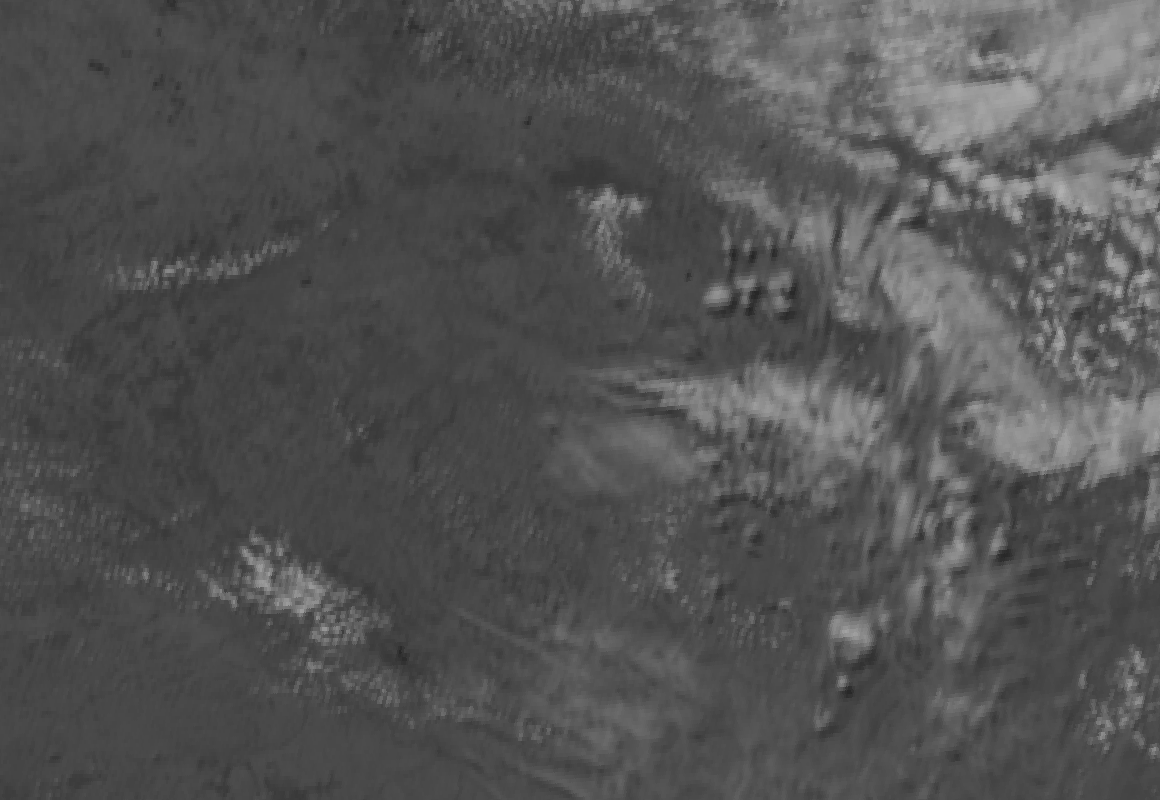

In [ ]:
cz_scene.show('HRV')

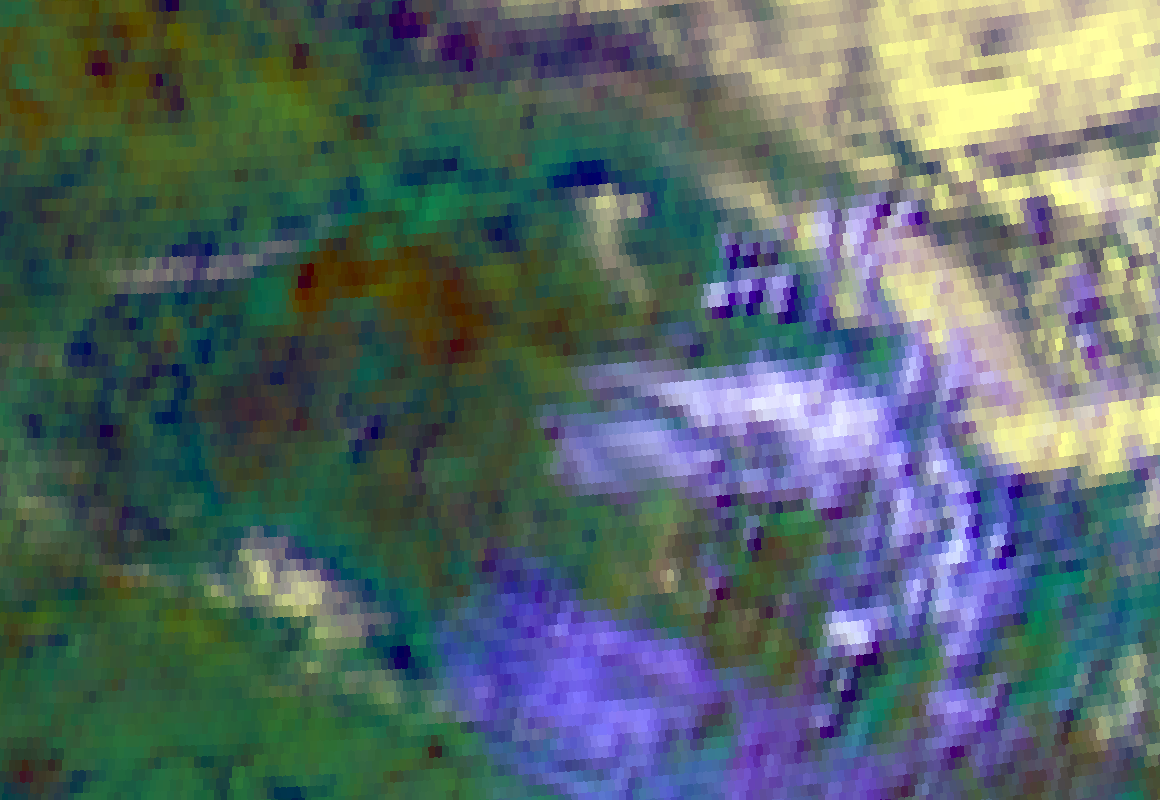

In [ ]:
cz_scene.show('overview')

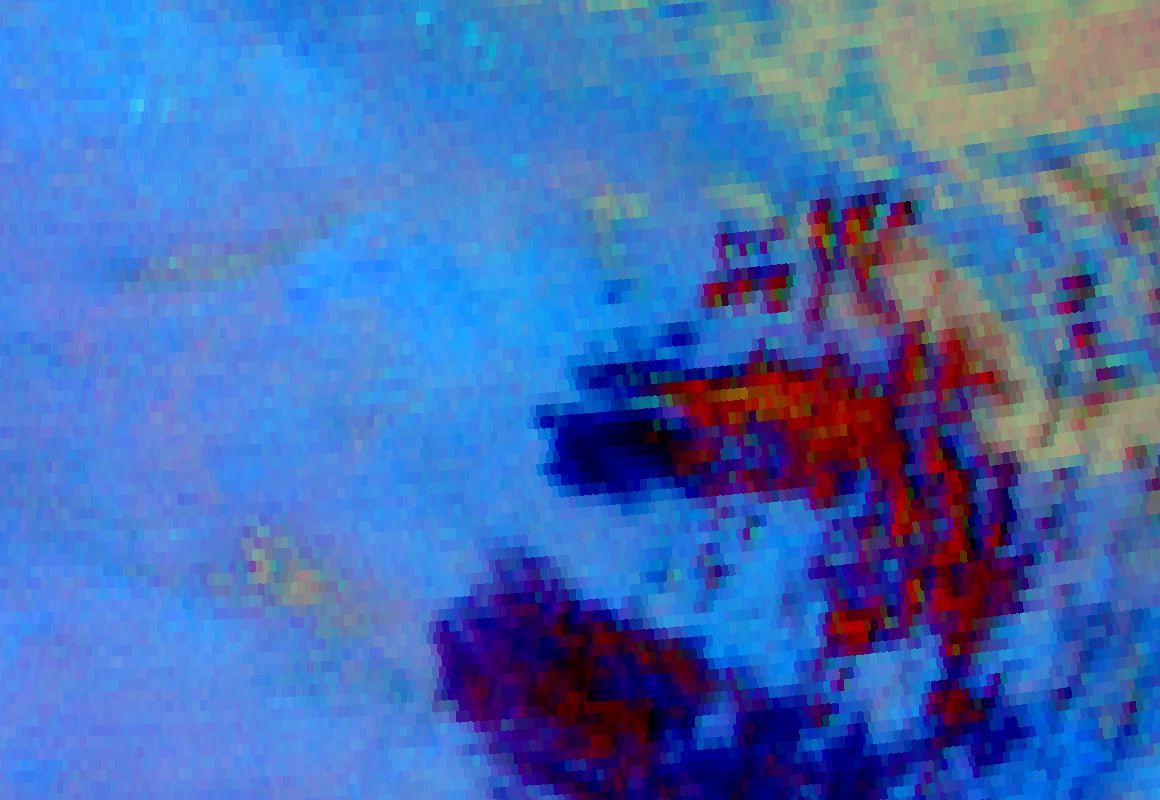

In [ ]:
cz_scene.show('24h_microphysics')

#Ukázka praktického využití

Stažení data ze specifickeho datumu. Už můžu použít jen čast kodu předchozího, nemusím importovat knihovny a řešit token.

In [ ]:
if consumer_key and consumer_secret:
    # Create a Datastore object
    token = eumdac.AccessToken((consumer_key, consumer_secret))
    datastore = eumdac.DataStore(token)

    # Define the product ID for MSG Level 1.5 SEVIRI data
    # You can find product IDs on the EUMETSAT Data Store website
    # Make sure to replace this with the actual product ID for the data you want
    product_id = 'MSG-SEVIRI-MSG15-0100-NA' # This is an example product ID, check EUMETSAT for the correct one.

    # Define the time range for the last hour
    end_time = datetime(2025, 4, 30, 20, 15) # Get the current time in UTC
    start_time = end_time - timedelta(hours=0.25) # Calculate the start time one hour ago

    # Selecting the collection and product.
    selected_collection = datastore.get_collection('EO:EUM:DAT:MSG:HRSEVIRI')

    # Search for data
    try:
        selected_products = selected_collection.search(dtstart = start_time, dtend = end_time)
        print(f'Found Datasets: {selected_products.total_results} datasets for the given time range')

        # Download the products
        if selected_products:
            print(f"Found {len(selected_products)} products. Downloading...")
            for product in selected_products:
                print(f"Product: {product}")
                try:
                    with product.open() as fsrc, \
                        open(fsrc.name, mode='wb') as fdst:
                        shutil.copyfileobj(fsrc, fdst)
                    print(f'Download of product {product} is finished.')
                except eumdac.product.ProductError as error:
                    print(f"Error related to the product '{product}' while trying to download it: '{error.msg}'")
                except requests.exceptions.ConnectionError as error:
                    print(f"Error related to the connection: '{error.msg}'")
                except requests.exceptions.RequestException as error:
                    print(f"Unexpected error: {error}")
        else:
            print("No products found for the specified criteria.")

    except Exception as e:
        print(f"An error occurred: {e}")

Found Datasets: 1 datasets for the given time range
Found 1 products. Downloading...
Product: MSG3-SEVI-MSG15-0100-NA-20250430201243.439000000Z-NA
Download of product MSG3-SEVI-MSG15-0100-NA-20250430201243.439000000Z-NA is finished.


In [ ]:
!unzip -o MSG3-SEVI-MSG15-0100-NA-20250430201243.439000000Z-NA.zip

Archive:  MSG3-SEVI-MSG15-0100-NA-20250430201243.439000000Z-NA.zip
replace manifest.xml? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace EOPMetadata.xml? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
  inflating: MSG3-SEVI-MSG15-0100-NA-20250430201243.439000000Z-NA.nat  


In [ ]:
!ls

EOPMetadata.xml
manifest.xml
MSG3-SEVI-MSG15-0100-NA-20250430201243.439000000Z-NA.nat
MSG3-SEVI-MSG15-0100-NA-20250430201243.439000000Z-NA.zip
MSG3-SEVI-MSG15-0100-NA-20250814061242.858000000Z-NA.nat
MSG3-SEVI-MSG15-0100-NA-20250814061242.858000000Z-NA.zip
sample_data


Kouknu se, co nám MSG, resp. SEVIRI data ukazují. Načtení dat už známe.

In [ ]:
filename_fire=glob("MSG3-SEVI-MSG15-0100-NA-20250430201243.439000000Z-NA.nat")
filename_fire

['MSG3-SEVI-MSG15-0100-NA-20250430201243.439000000Z-NA.nat']

In [ ]:
global_scene_fires= Scene(filenames=filename_fire)

ERROR:satpy.readers.core.loading:Problem with ['/usr/local/lib/python3.11/dist-packages/satpy/etc/readers/seviri_l1b_icare.yaml']
ERROR:satpy.readers.core.loading:while constructing a Python object
cannot find module 'satpy.readers.seviri_l1b_icare' (No module named 'pyhdf')
  in "/usr/local/lib/python3.11/dist-packages/satpy/etc/readers/seviri_l1b_icare.yaml", line 20, column 22
ERROR:satpy.readers.core.loading:Problem with ['/usr/local/lib/python3.11/dist-packages/satpy/etc/readers/seviri_l2_bufr.yaml']
ERROR:satpy.readers.core.loading:while constructing a Python object
cannot find module 'satpy.readers.eum_l2_bufr' (Missing eccodes-python and/or eccodes C-library installation. Use conda to install eccodes)
  in "/usr/local/lib/python3.11/dist-packages/satpy/etc/readers/seviri_l2_bufr.yaml", line 14, column 18
ERROR:satpy.readers.core.loading:Problem with ['/usr/local/lib/python3.11/dist-packages/satpy/etc/readers/avhrr_l1b_gaclac.yaml']
ERROR:satpy.readers.core.loading:while constru

In [ ]:
global_scene_fires.load(['night_microphysics'])

In [ ]:
cz_scene_fires = global_scene_fires.resample(my_area,radius_of_influence=10000)

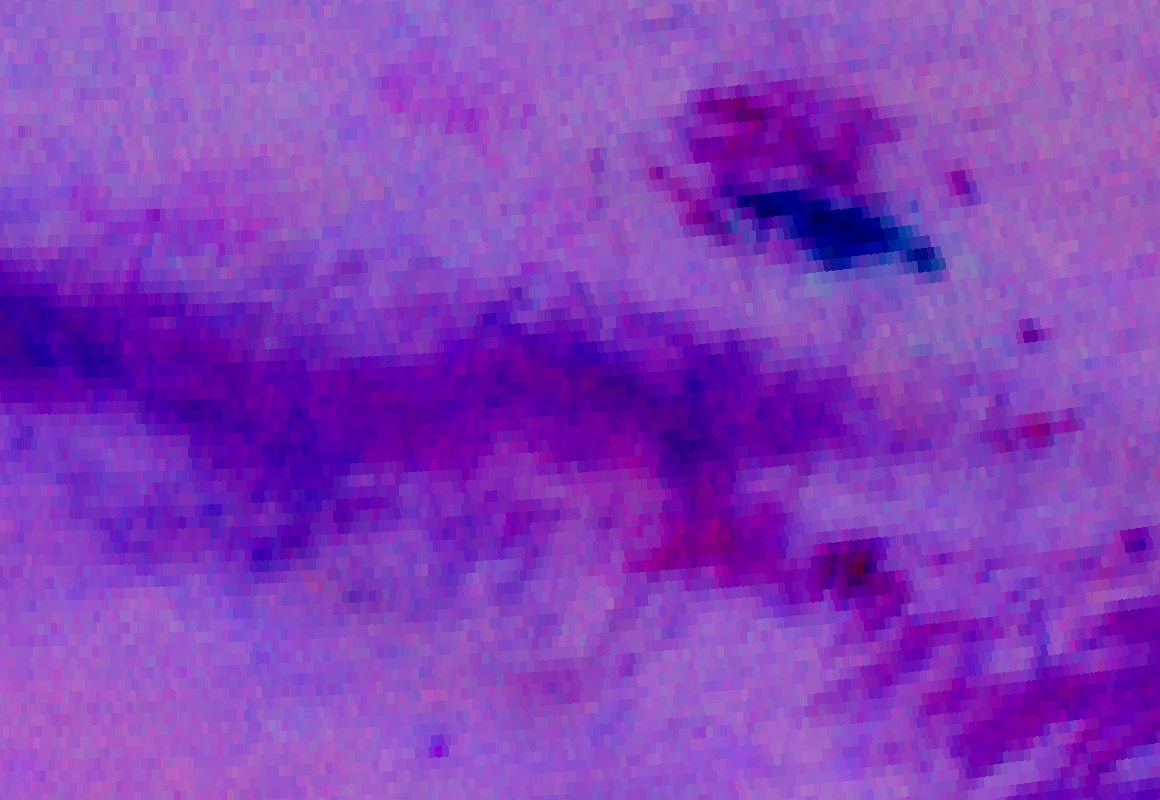

In [ ]:
cz_scene_fires.show('night_microphysics')

*MSG*, resp. přístroj SEVIRI má na lepší identifikaci horší rozlišení, ale něco tušit v růžové jde.

<img src="https://user.eumetsat.int/s3/eup-strapi-media/mtg_design_pixel_projections_web_b19f4b40de.png">

#Otázka : Co myslíte, že by mohly byt narůžovělé skvrny?


Zkusíme MTG a přístroj FCI

In [ ]:
!eumdac describe

EO:EUM:DAT:0959 - IASI Carbon Monoxide Profiles FORLI-CO Climate Data Record Release 1 - Metop-A and -B
EO:EUM:DAT:0960 - IASI SO2 Climate Data Record Release 1 - Metop-A and -B
EO:EUM:DAT:0962 - SEVIRI Rapid Scan High Rate Level 1.5 Image Data Climate Data Record Release 1 - MSG
EO:EUM:DAT:0961 - HIRS Level 1C Fundamental Data Record Release 2 - Multimission - Global
EO:EUM:DAT:0964 - SSM/T Level 1C Fundamental Data Record Release 1 - Multimission - Global
EO:EUM:DAT:0963 - SI-1 Fundamental Data Record Release 1 - Meteor - Polar
EO:EUM:DAT:0986 - Deep Convective Cloud System Monitoring Database - TOOCAN v2.08 Africa
EO:EUM:DAT:0987 - Deep Convective Cloud System Monitoring Database - CACATOES v1.04 Africa
EO:EUM:DAT:0908 - Auxiliary data TLE – AWS PFM
EO:EUM:DAT:METOP:AVHRRL1 - AVHRR Level 1B - Metop - Global
EO:EUM:DAT:METOP:SOMO25 - ASCAT Soil Moisture at 25 km Swath Grid in NRT - Metop
EO:EUM:DAT:METOP:SOMO12 - ASCAT Soil Moisture at 12.5 km Swath Grid in NRT - Metop
EO:EUM:DAT:079

Musíme změnit collection v kodu pro [FDHSI](https://user.eumetsat.int/resources/user-guides/mtg-fci-level-1c-data-guide) data je to EO:EUM:DAT:0662 a pro [HRFI](https://user.eumetsat.int/resources/user-guides/mtg-fci-level-1c-data-guide) EO:EUM:DAT:0665

In [ ]:
import eumdac
from datetime import datetime, timedelta
from google.colab import userdata
import requests
import shutil

# Get consumer key and secret from Colab Secrets Manager
# Add your EUMETSAT_CONSUMER_KEY and EUMETSAT_CONSUMER_SECRET to the Secrets Manager
try:
    consumer_key = userdata.get('EUMETSAT_CONSUMER_KEY')
    consumer_secret = userdata.get('EUMETSAT_CONSUMER_SECRET')

except Exception as e:
    print(f"Error retrieving credentials from Secrets Manager: {e}")
    print("Please add your EUMETSAT_CONSUMER_KEY and EUMETSAT_CONSUMER_SECRET to Colab's Secrets Manager.")
    consumer_key = None
    consumer_secret = None

In [ ]:
if consumer_key and consumer_secret:
    # Create a Datastore object
    token = eumdac.AccessToken((consumer_key, consumer_secret))
    datastore = eumdac.DataStore(token)

    # Define the product ID for MSG Level 1.5 SEVIRI data
    # You can find product IDs on the EUMETSAT Data Store website
    # Make sure to replace this with the actual product ID for the data you want
    product_id = 'MSG-SEVIRI-MSG15-0100-NA' # This is an example product ID, check EUMETSAT for the correct one.

    # Define the time range for the last hour
    end_time = datetime(2025, 4, 30, 20, 15) # Get the current time in UTC
    start_time = end_time - timedelta(hours=0.1) # Calculate the start time one hour ago

    # Selecting the collection and product.
    selected_collection = datastore.get_collection('EO:EUM:DAT:0662')

    # Search for data
    try:
        selected_products = selected_collection.search(dtstart = start_time, dtend = end_time)
        print(f'Found Datasets: {selected_products.total_results} datasets for the given time range')

        # Download the products
        if selected_products:
            print(f"Found {len(selected_products)} products. Downloading...")
            for product in selected_products:
                print(f"Product: {product}")
                try:
                    with product.open() as fsrc, \
                        open(fsrc.name, mode='wb') as fdst:
                        shutil.copyfileobj(fsrc, fdst)
                    print(f'Download of product {product} is finished.')
                except eumdac.product.ProductError as error:
                    print(f"Error related to the product '{product}' while trying to download it: '{error.msg}'")
                except requests.exceptions.ConnectionError as error:
                    print(f"Error related to the connection: '{error.msg}'")
                except requests.exceptions.RequestException as error:
                    print(f"Unexpected error: {error}")
        else:
            print("No products found for the specified criteria.")

    except Exception as e:
        print(f"An error occurred: {e}")

Found Datasets: 2 datasets for the given time range
Found 2 products. Downloading...
Product: W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-FDHSI-FD--x-x---x_C_EUMT_20250430201313_IDPFI_OPE_20250430201007_20250430201935_N__O_0122_0000
Download of product W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-FDHSI-FD--x-x---x_C_EUMT_20250430201313_IDPFI_OPE_20250430201007_20250430201935_N__O_0122_0000 is finished.
Product: W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-FDHSI-FD--x-x---x_C_EUMT_20250430200308_IDPFI_OPE_20250430200007_20250430200935_N__O_0121_0000
Download of product W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-FDHSI-FD--x-x---x_C_EUMT_20250430200308_IDPFI_OPE_20250430200007_20250430200935_N__O_0121_0000 is finished.


In [ ]:
if consumer_key and consumer_secret:
    # Create a Datastore object
    token = eumdac.AccessToken((consumer_key, consumer_secret))
    datastore = eumdac.DataStore(token)

    # Define the product ID for MSG Level 1.5 SEVIRI data
    # You can find product IDs on the EUMETSAT Data Store website
    # Make sure to replace this with the actual product ID for the data you want
    product_id = 'MSG-SEVIRI-MSG15-0100-NA' # This is an example product ID, check EUMETSAT for the correct one.

    # Define the time range for the last hour
    end_time = datetime(2025, 4, 30, 20, 15) # Get the current time in UTC
    start_time = end_time - timedelta(hours=0.1) # Calculate the start time one hour ago

    # Selecting the collection and product.
    selected_collection = datastore.get_collection('EO:EUM:DAT:0665')

    # Search for data
    try:
        selected_products = selected_collection.search(dtstart = start_time, dtend = end_time)
        print(f'Found Datasets: {selected_products.total_results} datasets for the given time range')

        # Download the products
        if selected_products:
            print(f"Found {len(selected_products)} products. Downloading...")
            for product in selected_products:
                print(f"Product: {product}")
                try:
                    with product.open() as fsrc, \
                        open(fsrc.name, mode='wb') as fdst:
                        shutil.copyfileobj(fsrc, fdst)
                    print(f'Download of product {product} is finished.')
                except eumdac.product.ProductError as error:
                    print(f"Error related to the product '{product}' while trying to download it: '{error.msg}'")
                except requests.exceptions.ConnectionError as error:
                    print(f"Error related to the connection: '{error.msg}'")
                except requests.exceptions.RequestException as error:
                    print(f"Unexpected error: {error}")
        else:
            print("No products found for the specified criteria.")

    except Exception as e:
        print(f"An error occurred: {e}")

Found Datasets: 2 datasets for the given time range
Found 2 products. Downloading...
Product: W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-HRFI-FD--x-x---x_C_EUMT_20250430201313_IDPFI_OPE_20250430201007_20250430201935_N__O_0122_0000
Download of product W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-HRFI-FD--x-x---x_C_EUMT_20250430201313_IDPFI_OPE_20250430201007_20250430201935_N__O_0122_0000 is finished.
Product: W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-HRFI-FD--x-x---x_C_EUMT_20250430200308_IDPFI_OPE_20250430200007_20250430200935_N__O_0121_0000
Download of product W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-HRFI-FD--x-x---x_C_EUMT_20250430200308_IDPFI_OPE_20250430200007_20250430200935_N__O_0121_0000 is finished.


In [ ]:
!ls

EOPMetadata.xml
manifest.xml
MSG3-SEVI-MSG15-0100-NA-20250430201243.439000000Z-NA.nat
MSG3-SEVI-MSG15-0100-NA-20250430201243.439000000Z-NA.zip
MSG3-SEVI-MSG15-0100-NA-20250814061242.858000000Z-NA.nat
MSG3-SEVI-MSG15-0100-NA-20250814061242.858000000Z-NA.zip
sample_data
W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-FDHSI-FD--x-x---x_C_EUMT_20250430200308_IDPFI_OPE_20250430200007_20250430200935_N__O_0121_0000.zip
W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-FDHSI-FD--x-x---x_C_EUMT_20250430201313_IDPFI_OPE_20250430201007_20250430201935_N__O_0122_0000.zip
W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-HRFI-FD--x-x---x_C_EUMT_20250430200308_IDPFI_OPE_20250430200007_20250430200935_N__O_0121_0000.zip
W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-HRFI-FD--x-x---x_C_EUMT_20250430201313_IDPFI_OPE_20250430201007_20250430201935_N__O_0122_0000.zip


In [ ]:
!unzip -o W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-HRFI-FD--x-x---x_C_EUMT_20250430200308_IDPFI_OPE_20250430200007_20250430200935_N__O_0121_0000.zip

Archive:  W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-HRFI-FD--x-x---x_C_EUMT_20250430200308_IDPFI_OPE_20250430200007_20250430200935_N__O_0121_0000.zip
  inflating: W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-HRFI-FD--CHK-BODY---NC4E_C_EUMT_20250430200832_IDPFI_OPE_20250430200530_20250430200619_N__O_0121_0024.nc  
  inflating: W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-HRFI-FD--CHK-BODY---NC4E_C_EUMT_20250430201015_IDPFI_OPE_20250430200735_20250430200826_N__O_0121_0032.nc  
  inflating: W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-HRFI-FD--CHK-BODY---NC4E_C_EUMT_20250430201025_IDPFI_OPE_20250430200744_20250430200834_N__O_0121_0033.nc  
  inflating: W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-HRFI-FD--CHK-BODY---NC4E_C_EUMT_20250430200842_IDPFI_OPE_20250430200540_20250430200629_N__O_0121_0025.nc  
  inflating: W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-HRFI-FD--CHK-BODY---NC4E_C_EUMT_20250430201000_IDPFI_OPE_20250430200707_20250430200801_N__O_0121_0030.nc 

In [ ]:
!unzip -o W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-FDHSI-FD--x-x---x_C_EUMT_20250430200308_IDPFI_OPE_20250430200007_20250430200935_N__O_0121_0000.zip

Archive:  W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-FDHSI-FD--x-x---x_C_EUMT_20250430200308_IDPFI_OPE_20250430200007_20250430200935_N__O_0121_0000.zip
  inflating: W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-FDHSI-FD--CHK-BODY---NC4E_C_EUMT_20250430201051_IDPFI_OPE_20250430200826_20250430200911_N__O_0121_0036.nc  
  inflating: W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-FDHSI-FD--CHK-BODY---NC4E_C_EUMT_20250430200923_IDPFI_OPE_20250430200629_20250430200726_N__O_0121_0028.nc  
  inflating: W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-FDHSI-FD--CHK-BODY---NC4E_C_EUMT_20250430200541_IDPFI_OPE_20250430200107_20250430200149_N__O_0121_0008.nc  
  inflating: W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-FDHSI-FD--CHK-BODY---NC4E_C_EUMT_20250430201102_IDPFI_OPE_20250430200917_20250430200935_N__O_0121_0040.nc  
  inflating: W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-FDHSI-FD--CHK-BODY---NC4E_C_EUMT_20250430200602_IDPFI_OPE_20250430200141_20250430200225_N__O_0121_00

In [ ]:
filename_fire_FCI_FDHSI=glob("W*FDHSI*0036.nc")
filename_fire_FCI_FDHSI

['W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-FDHSI-FD--CHK-BODY---NC4E_C_EUMT_20250430201051_IDPFI_OPE_20250430200826_20250430200911_N__O_0121_0036.nc']

In [ ]:
filename_fire_FCI_FDHSI.append(glob("W*FDHSI*0037.nc")[0])
filename_fire_FCI_FDHSI

['W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-FDHSI-FD--CHK-BODY---NC4E_C_EUMT_20250430201051_IDPFI_OPE_20250430200826_20250430200911_N__O_0121_0036.nc',
 'W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-FDHSI-FD--CHK-BODY---NC4E_C_EUMT_20250430201056_IDPFI_OPE_20250430200842_20250430200924_N__O_0121_0037.nc']

In [ ]:
filename_fire_FCI_HRFI=glob("W*HRFI*0036.nc")
filename_fire_FCI_HRFI

['W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-HRFI-FD--CHK-BODY---NC4E_C_EUMT_20250430201051_IDPFI_OPE_20250430200826_20250430200911_N__O_0121_0036.nc']

In [ ]:
filename_fire_FCI_HRFI.append(glob("W*HRFI*0037.nc")[0])
filename_fire_FCI_HRFI

['W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-HRFI-FD--CHK-BODY---NC4E_C_EUMT_20250430201051_IDPFI_OPE_20250430200826_20250430200911_N__O_0121_0036.nc',
 'W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-HRFI-FD--CHK-BODY---NC4E_C_EUMT_20250430201056_IDPFI_OPE_20250430200842_20250430200924_N__O_0121_0037.nc']

In [ ]:
filename_fire_FCI_HRFI

['W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-HRFI-FD--CHK-BODY---NC4E_C_EUMT_20250430201051_IDPFI_OPE_20250430200826_20250430200911_N__O_0121_0036.nc',
 'W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-HRFI-FD--CHK-BODY---NC4E_C_EUMT_20250430201056_IDPFI_OPE_20250430200842_20250430200924_N__O_0121_0037.nc']

Pronacteni potrebujeme jeste jeden plugin

In [ ]:
globe_scene_fires_FCI_FDHSI=Scene(filenames=filename_fire_FCI_FDHSI)

ERROR:satpy.readers.core.loading:Problem with ['/usr/local/lib/python3.11/dist-packages/satpy/etc/readers/seviri_l1b_icare.yaml']
ERROR:satpy.readers.core.loading:while constructing a Python object
cannot find module 'satpy.readers.seviri_l1b_icare' (No module named 'pyhdf')
  in "/usr/local/lib/python3.11/dist-packages/satpy/etc/readers/seviri_l1b_icare.yaml", line 20, column 22
ERROR:satpy.readers.core.loading:Problem with ['/usr/local/lib/python3.11/dist-packages/satpy/etc/readers/seviri_l2_bufr.yaml']
ERROR:satpy.readers.core.loading:while constructing a Python object
cannot find module 'satpy.readers.eum_l2_bufr' (Missing eccodes-python and/or eccodes C-library installation. Use conda to install eccodes)
  in "/usr/local/lib/python3.11/dist-packages/satpy/etc/readers/seviri_l2_bufr.yaml", line 14, column 18
ERROR:satpy.readers.core.loading:Problem with ['/usr/local/lib/python3.11/dist-packages/satpy/etc/readers/avhrr_l1b_gaclac.yaml']
ERROR:satpy.readers.core.loading:while constru

In [ ]:
globe_scene_fires_FCI_HRFI=Scene(filenames=filename_fire_FCI_HRFI)

ERROR:satpy.readers.core.loading:Problem with ['/usr/local/lib/python3.11/dist-packages/satpy/etc/readers/seviri_l1b_icare.yaml']
ERROR:satpy.readers.core.loading:while constructing a Python object
cannot find module 'satpy.readers.seviri_l1b_icare' (No module named 'pyhdf')
  in "/usr/local/lib/python3.11/dist-packages/satpy/etc/readers/seviri_l1b_icare.yaml", line 20, column 22
ERROR:satpy.readers.core.loading:Problem with ['/usr/local/lib/python3.11/dist-packages/satpy/etc/readers/seviri_l2_bufr.yaml']
ERROR:satpy.readers.core.loading:while constructing a Python object
cannot find module 'satpy.readers.eum_l2_bufr' (Missing eccodes-python and/or eccodes C-library installation. Use conda to install eccodes)
  in "/usr/local/lib/python3.11/dist-packages/satpy/etc/readers/seviri_l2_bufr.yaml", line 14, column 18
ERROR:satpy.readers.core.loading:Problem with ['/usr/local/lib/python3.11/dist-packages/satpy/etc/readers/avhrr_l1b_gaclac.yaml']
ERROR:satpy.readers.core.loading:while constru

In [ ]:
globe_scene_fires_FCI_FDHSI.available_dataset_names()

['ir_105',
 'ir_105_earth_sun_distance',
 'ir_105_index_map',
 'ir_105_pixel_quality',
 'ir_105_platform_altitude',
 'ir_105_subsatellite_latitude',
 'ir_105_subsatellite_longitude',
 'ir_105_subsolar_latitude',
 'ir_105_subsolar_longitude',
 'ir_105_sun_satellite_distance',
 'ir_105_swath_direction',
 'ir_105_swath_number',
 'ir_105_time',
 'ir_123',
 'ir_123_earth_sun_distance',
 'ir_123_index_map',
 'ir_123_pixel_quality',
 'ir_123_platform_altitude',
 'ir_123_subsatellite_latitude',
 'ir_123_subsatellite_longitude',
 'ir_123_subsolar_latitude',
 'ir_123_subsolar_longitude',
 'ir_123_sun_satellite_distance',
 'ir_123_swath_direction',
 'ir_123_swath_number',
 'ir_123_time',
 'ir_133',
 'ir_133_earth_sun_distance',
 'ir_133_index_map',
 'ir_133_pixel_quality',
 'ir_133_platform_altitude',
 'ir_133_subsatellite_latitude',
 'ir_133_subsatellite_longitude',
 'ir_133_subsolar_latitude',
 'ir_133_subsolar_longitude',
 'ir_133_sun_satellite_distance',
 'ir_133_swath_direction',
 'ir_133_sw

In [ ]:
globe_scene_fires_FCI_FDHSI.available_composite_names()

['24h_microphysics',
 'airmass',
 'ash',
 'cimss_cloud_type',
 'cimss_cloud_type_raw',
 'cloud_phase',
 'cloud_phase_distinction',
 'cloud_phase_distinction_raw',
 'cloud_phase_raw',
 'cloud_phase_with_night_ir105',
 'cloud_type',
 'cloud_type_with_night_ir105',
 'cloudtop',
 'colorized_ir_clouds',
 'convection',
 'day_essl_colorized_low_level_moisture',
 'day_essl_low_level_moisture',
 'day_microphysics',
 'day_severe_storms',
 'day_severe_storms_tropical',
 'dust',
 'essl_colorized_low_level_moisture',
 'essl_low_level_moisture',
 'fci_fire_channels_sum',
 'fire_temperature',
 'fire_temperature_38refl',
 'fire_temperature_rad',
 'flames_masked',
 'fog',
 'geo_color',
 'geo_color_background_with_low_clouds',
 'geo_color_high_clouds',
 'geo_color_low_clouds',
 'geo_color_night',
 'green_snow',
 'hrv_clouds',
 'ir108_3d',
 'ir_cloud_day',
 'ir_sandwich',
 'ir_sandwich_with_night_colorized_ir_clouds',
 'natural_color',
 'natural_color_raw',
 'ndvi_hybrid_green',
 'ndvi_hybrid_green_fully

In [ ]:
globe_scene_fires_FCI_HRFI.available_dataset_names()

['ir_105',
 'ir_105_earth_sun_distance',
 'ir_105_index_map',
 'ir_105_pixel_quality',
 'ir_105_platform_altitude',
 'ir_105_subsatellite_latitude',
 'ir_105_subsatellite_longitude',
 'ir_105_subsolar_latitude',
 'ir_105_subsolar_longitude',
 'ir_105_sun_satellite_distance',
 'ir_105_swath_direction',
 'ir_105_swath_number',
 'ir_105_time',
 'ir_38',
 'ir_38_earth_sun_distance',
 'ir_38_index_map',
 'ir_38_pixel_quality',
 'ir_38_platform_altitude',
 'ir_38_subsatellite_latitude',
 'ir_38_subsatellite_longitude',
 'ir_38_subsolar_latitude',
 'ir_38_subsolar_longitude',
 'ir_38_sun_satellite_distance',
 'ir_38_swath_direction',
 'ir_38_swath_number',
 'ir_38_time',
 'nir_22',
 'nir_22_earth_sun_distance',
 'nir_22_index_map',
 'nir_22_pixel_quality',
 'nir_22_platform_altitude',
 'nir_22_subsatellite_latitude',
 'nir_22_subsatellite_longitude',
 'nir_22_subsolar_latitude',
 'nir_22_subsolar_longitude',
 'nir_22_sun_satellite_distance',
 'nir_22_swath_direction',
 'nir_22_swath_number',


In [ ]:
globe_scene_fires_FCI_HRFI.available_composite_names()

['colorized_ir_clouds',
 'fci_fire_channels_sum',
 'flames_masked',
 'geo_color_background_with_low_clouds',
 'geo_color_high_clouds',
 'geo_color_low_clouds',
 'geo_color_night',
 'hrv_clouds',
 'ir108_3d',
 'ir_cloud_day',
 'ir_sandwich',
 'ir_sandwich_with_night_colorized_ir_clouds',
 'night_ir105',
 'simple_fci_fire_mask']

In [ ]:
globe_scene_fires_FCI_FDHSI.load(['night_microphysics'])

/usr/local/lib/python3.11/dist-packages/numpy/_core/numeric.py:452: RuntimeWarning: invalid value encountered in cast
  multiarray.copyto(res, fill_value, casting='unsafe')
/usr/local/lib/python3.11/dist-packages/numpy/_core/numeric.py:452: RuntimeWarning: invalid value encountered in cast
  multiarray.copyto(res, fill_value, casting='unsafe')
/usr/local/lib/python3.11/dist-packages/numpy/_core/numeric.py:452: RuntimeWarning: invalid value encountered in cast
  multiarray.copyto(res, fill_value, casting='unsafe')


In [ ]:
cz_scene_fires_FCI_FDHSI = globe_scene_fires_FCI_FDHSI.resample(my_area,radius_of_influence=10000)

In [26]:
#cz_scene_fires_FCI_FDHSI.show('night_microphysics')

#Otázka: Růžové skvrny jsou spíš body, jednotlivé pixely. Už někdo víte?

In [ ]:
globe_scene_fires_FCI_HRFI.load(['fci_fire_channels_sum','ir_38','simple_fci_fire_mask'])

/usr/local/lib/python3.11/dist-packages/numpy/_core/numeric.py:452: RuntimeWarning: invalid value encountered in cast
  multiarray.copyto(res, fill_value, casting='unsafe')
/usr/local/lib/python3.11/dist-packages/numpy/_core/numeric.py:452: RuntimeWarning: invalid value encountered in cast
  multiarray.copyto(res, fill_value, casting='unsafe')
/usr/local/lib/python3.11/dist-packages/numpy/_core/numeric.py:452: RuntimeWarning: invalid value encountered in cast
  multiarray.copyto(res, fill_value, casting='unsafe')
/usr/local/lib/python3.11/dist-packages/numpy/_core/numeric.py:452: RuntimeWarning: invalid value encountered in cast
  multiarray.copyto(res, fill_value, casting='unsafe')


In [ ]:
cz_scene_fires_FCI_HRFI = globe_scene_fires_FCI_HRFI.resample(my_area,radius_of_influence=10000)

In [27]:
#cz_scene_fires_FCI_HRFI.show('fci_fire_channels_sum')

#Tak zkusme polárky. V archivu EUMETSATu jsou [Metopy](https://www.eumetsat.int/our-satellites/metop-series)

In [ ]:
!eumdac describe

EO:EUM:DAT:0959 - IASI Carbon Monoxide Profiles FORLI-CO Climate Data Record Release 1 - Metop-A and -B
EO:EUM:DAT:0960 - IASI SO2 Climate Data Record Release 1 - Metop-A and -B
EO:EUM:DAT:0962 - SEVIRI Rapid Scan High Rate Level 1.5 Image Data Climate Data Record Release 1 - MSG
EO:EUM:DAT:0961 - HIRS Level 1C Fundamental Data Record Release 2 - Multimission - Global
EO:EUM:DAT:0964 - SSM/T Level 1C Fundamental Data Record Release 1 - Multimission - Global
EO:EUM:DAT:0963 - SI-1 Fundamental Data Record Release 1 - Meteor - Polar
EO:EUM:DAT:0986 - Deep Convective Cloud System Monitoring Database - TOOCAN v2.08 Africa
EO:EUM:DAT:0987 - Deep Convective Cloud System Monitoring Database - CACATOES v1.04 Africa
EO:EUM:DAT:0908 - Auxiliary data TLE – AWS PFM
EO:EUM:DAT:METOP:AVHRRL1 - AVHRR Level 1B - Metop - Global
EO:EUM:DAT:METOP:SOMO25 - ASCAT Soil Moisture at 25 km Swath Grid in NRT - Metop
EO:EUM:DAT:METOP:SOMO12 - ASCAT Soil Moisture at 12.5 km Swath Grid in NRT - Metop
EO:EUM:DAT:079

In [ ]:
if consumer_key and consumer_secret:
    # Create a Datastore object
    token = eumdac.AccessToken((consumer_key, consumer_secret))
    datastore = eumdac.DataStore(token)

    # Define the product ID for MSG Level 1.5 SEVIRI data
    # You can find product IDs on the EUMETSAT Data Store website
    # Make sure to replace this with the actual product ID for the data you want
    product_id = 'MSG-SEVIRI-MSG15-0100-NA' # This is an example product ID, check EUMETSAT for the correct one.

    # Define the time range for the last hour
    end_time = datetime(2025, 4, 30, 20, 00) # Get the current time in UTC
    start_time = end_time - timedelta(hours=1) # Calculate the start time one hour ago

    # Selecting the collection and product.
    selected_collection = datastore.get_collection('EO:EUM:DAT:METOP:AVHRRL1')

    # Search for data
    try:
        selected_products = selected_collection.search(dtstart = start_time, dtend = end_time)
        print(f'Found Datasets: {selected_products.total_results} datasets for the given time range')

        # Download the products
        if selected_products:
            print(f"Found {len(selected_products)} products. Downloading...")
            for product in selected_products:
                print(f"Product: {product}")
                try:
                    with product.open() as fsrc, \
                        open(fsrc.name, mode='wb') as fdst:
                        shutil.copyfileobj(fsrc, fdst)
                    print(f'Download of product {product} is finished.')
                except eumdac.product.ProductError as error:
                    print(f"Error related to the product '{product}' while trying to download it: '{error.msg}'")
                except requests.exceptions.ConnectionError as error:
                    print(f"Error related to the connection: '{error.msg}'")
                except requests.exceptions.RequestException as error:
                    print(f"Unexpected error: {error}")
        else:
            print("No products found for the specified criteria.")

    except Exception as e:
        print(f"An error occurred: {e}")

Found Datasets: 3 datasets for the given time range
Found 3 products. Downloading...
Product: AVHR_xxx_1B_M03_20250430194603Z_20250430212803Z_N_O_20250430212306Z
Download of product AVHR_xxx_1B_M03_20250430194603Z_20250430212803Z_N_O_20250430212306Z is finished.
Product: AVHR_xxx_1B_M01_20250430185503Z_20250430203703Z_N_O_20250430194340Z
Download of product AVHR_xxx_1B_M01_20250430185503Z_20250430203703Z_N_O_20250430194340Z is finished.
Product: AVHR_xxx_1B_M03_20250430180403Z_20250430194603Z_N_O_20250430194131Z
Download of product AVHR_xxx_1B_M03_20250430180403Z_20250430194603Z_N_O_20250430194131Z is finished.


In [ ]:
!ls

AVHR_xxx_1B_M01_20250430185503Z_20250430203703Z_N_O_20250430194340Z.zip
AVHR_xxx_1B_M03_20250430180403Z_20250430194603Z_N_O_20250430194131Z.zip
AVHR_xxx_1B_M03_20250430194603Z_20250430212803Z_N_O_20250430212306Z.zip
EOPMetadata.xml
manifest.xml
MSG3-SEVI-MSG15-0100-NA-20250430201243.439000000Z-NA.nat
MSG3-SEVI-MSG15-0100-NA-20250430201243.439000000Z-NA.zip
MSG3-SEVI-MSG15-0100-NA-20250814061242.858000000Z-NA.nat
MSG3-SEVI-MSG15-0100-NA-20250814061242.858000000Z-NA.zip
quicklooks
sample_data
W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-FDHSI-FD--CHK-BODY---NC4E_C_EUMT_20250430200436_IDPFI_OPE_20250430200007_20250430200024_N__O_0121_0001.nc
W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-FDHSI-FD--CHK-BODY---NC4E_C_EUMT_20250430200444_IDPFI_OPE_20250430200007_20250430200031_N__O_0121_0002.nc
W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FCI-1C-RRAD-FDHSI-FD--CHK-BODY---NC4E_C_EUMT_20250430200457_IDPFI_OPE_20250430200018_20250430200045_N__O_0121_0003.nc
W_XX-EUMETSAT-Darmstadt,IMG+SAT,MTI1+FC

In [ ]:
!unzip -o AVHR_xxx_1B_M03_20250430180403Z_20250430194603Z_N_O_20250430194131Z.zip

Archive:  AVHR_xxx_1B_M03_20250430180403Z_20250430194603Z_N_O_20250430194131Z.zip
  inflating: AVHR_xxx_1B_M03_20250430180403Z_20250430194603Z_N_O_20250430194131Z.nat  
  inflating: manifest.xml            
  inflating: EOPMetadata.xml         


In [ ]:
filename_fire_AVHRR = glob("AVHR_xxx_1B_M03_20250430180403Z_20250430194603Z_N_O_20250430194131Z.nat")
filename_fire_AVHRR

['AVHR_xxx_1B_M03_20250430180403Z_20250430194603Z_N_O_20250430194131Z.nat']

In [ ]:
globe_scene = Scene(filenames=filename_fire_AVHRR)

ERROR:satpy.readers.core.loading:Problem with ['/usr/local/lib/python3.11/dist-packages/satpy/etc/readers/fci_l2_grib.yaml']
ERROR:satpy.readers.core.loading:while constructing a Python object
cannot find module 'satpy.readers.eum_l2_grib' (Missing eccodes-python and/or eccodes C-library installation. Use conda to install eccodes)
  in "/usr/local/lib/python3.11/dist-packages/satpy/etc/readers/fci_l2_grib.yaml", line 13, column 18


In [ ]:
globe_scene.available_composite_names()

['cloud_phase_distinction',
 'cloud_phase_distinction_raw',
 'cloudtop',
 'day_essl_colorized_low_level_moisture',
 'day_essl_low_level_moisture',
 'day_microphysics',
 'essl_colorized_low_level_moisture',
 'essl_low_level_moisture',
 'green_snow',
 'ir108_3d',
 'ir_cloud_day',
 'natural_color',
 'natural_color_raw',
 'natural_enh',
 'natural_with_night_fog',
 'night_fog',
 'night_microphysics',
 'night_microphysics_tropical',
 'overview',
 'overview_raw',
 'snow']

In [ ]:
globe_scene.load(["day_microphysics"])

In [ ]:
cz_scene_fires_AVHRR = globe_scene.resample(my_area,radius_of_influence=10000)

In [28]:
#cz_scene_fires_AVHRR.show("day_microphysics")

Ideální by byl produkt noční mikrofyzikal, ale to už mi colab kvůli paměti padal. Tady ukázka našeho operativního produktu.

<img src="https://ecloud.chmi.cz/apps/files_sharing/publicpreview/t4ryenZPDMLTn5A?file=/&fileId=709831&x=2560&y=1440&a=true&etag=5f8d39466c10380edaeefd55d252f99b">

#Otázka: Co myslíte, že by mohly být narůžovělé skvrny?

#Závěr

Detekci a monitoringem požárů se zabývá pro Evropu projekt [EFFIS](https://forest-fire.emergency.copernicus.eu/applications) a i u nas je o detekci a monitoring po Českem Švýcarsku větší zájem. Na CHMU vyhodnocujeme v rámci diplomové práce na MFF UK pomocí Bayesovskeho modelu, jaký má detekce u nás význam. Minimalně občas má, jak potvrzuje članek a rozbor použití EFFISu [zde](https://ekolist.cz/cz/publicistika/nazory-a-komentare/miroslav-havranek-pozar-v-ceskem-svycarsku-z-pohledu-satelitnich-dat)

Záleží na typu družice a toho kdy snímá dané území. Obecně platí polárky rovná se lepší rozlišení, ale data méně často. Geostacionarky rovná se data často, ale za cenu horšího rozlišení. Např. pro předpověď počasí je dynamika snímaných jevů extrémně důležitá. Pro DPZ aplikace už je spíš důležitější rozlišení.